<a href="https://colab.research.google.com/github/emrizky1/machine-learning/blob/main/JS07/JS07_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [4]:
df = pd.read_csv('CC_Customer_Dataset.csv')
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


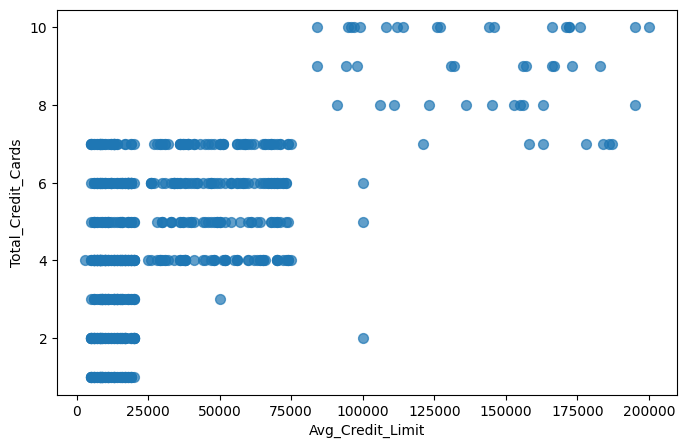

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], s=50, alpha=0.7)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.show()

The distribution of customers does not form a clear straight line. The number of credit cards also tends to take on discrete values, while the credit limit has a wide range. Therefore, the distribution of these two variables cannot be considered to have a strong linear relationship based solely on the scatter plot.

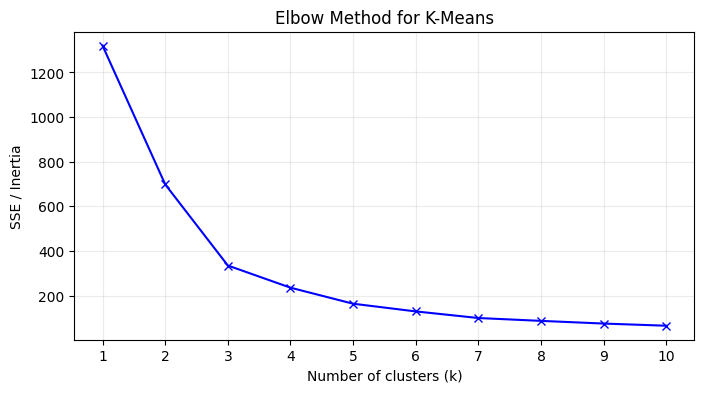

,k,SSE
0,1,1320.000000
1,2,698.293332
2,3,334.724473
3,4,235.392749
4,5,163.471841
5,6,128.964269
6,7,99.370108
7,8,86.534485
8,9,74.530179
9,10,64.826390


In [10]:
features_kmeans = ['Avg_Credit_Limit', 'Total_Credit_Cards']
X_kmeans = df[features_kmeans]

scaler_kmeans = StandardScaler()
X_kmeans_scaled = scaler_kmeans.fit_transform(X_kmeans)

sse = []
K = range(1, 11)

for k in K:
    kmeans_model = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_model.fit(X_kmeans_scaled)
    sse.append(kmeans_model.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K, sse, 'bx-')
plt.xlabel('Number of clusters (k)')
plt.ylabel('SSE / Inertia')
plt.title('Elbow Method for K-Means')
plt.xticks(list(K))
plt.grid(alpha=0.25)
plt.show()

pd.DataFrame({'k': list(K), 'SSE': sse})

The most significant drop in SSE occurs from k=1 to k=3, after which the decrease starts to level off. In this notebook, k=3 is chosen as a compromise between achieving a lower SSE and keeping the number of clusters manageable. The elbow method is inherently visual, meaning this choice is an interpretation of the graph's pattern rather than the only possible correct answer.

In [35]:
k_optimal = 3
kmeans_model = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_kmeans_scaled)

print('Jumlah anggota tiap cluster:')
print(pd.Series(kmeans_labels).value_counts().sort_index())
print(f'Silhouette Score K-Means: {silhouette_score(X_kmeans_scaled, kmeans_labels):.4f}')

Jumlah anggota tiap cluster:
0    330
1     48
2    282
Name: count, dtype: int64
Silhouette Score K-Means: 0.4901


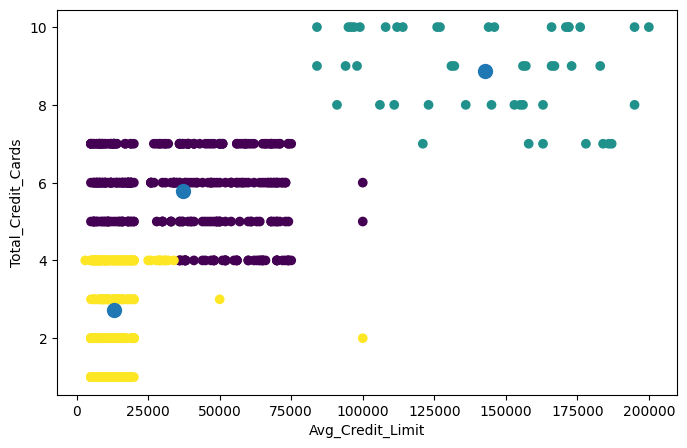

In [36]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], c=kmeans_labels, cmap='viridis',)

centers_original = scaler_kmeans.inverse_transform(kmeans_model.cluster_centers_)
plt.scatter(centers_original[:, 0], centers_original[:, 1], s = 100)

plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.show()

In [37]:
features_dbscan = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]

X_dbscan = df[features_dbscan]
scaler_dbscan = StandardScaler()
X_dbscan_scaled = scaler_dbscan.fit_transform(X_dbscan)

print('Used Feature', features_dbscan)
print('Data size:', X_dbscan_scaled.shape)

Used Feature ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
Data size: (660, 5)


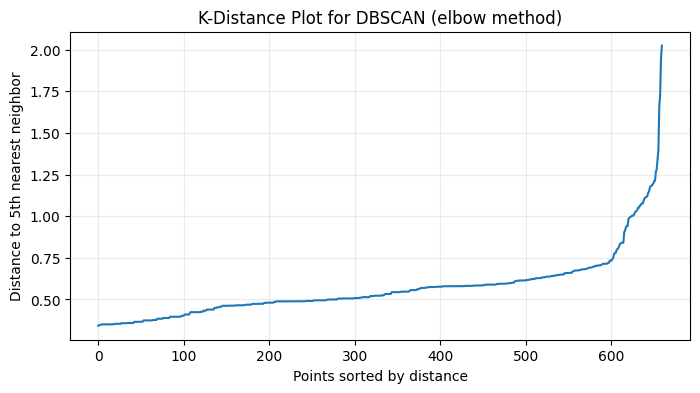

In [38]:
min_samples = 5
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_dbscan_scaled)
distances, indices = neighbors_fit.kneighbors(X_dbscan_scaled)

k_distances = np.sort(distances[:, min_samples - 1])

plt.figure(figsize=(8, 4))
plt.plot(k_distances)
plt.xlabel('Points sorted by distance')
plt.ylabel(f'Distance to {min_samples}th nearest neighbor')
plt.title('K-Distance Plot for DBSCAN (elbow method)')
plt.grid(alpha=0.25)
plt.show()

In [39]:
eps_optimal = 1.0
dbscan_model = DBSCAN(eps=eps_optimal, min_samples=min_samples)
dbscan_labels = dbscan_model.fit_predict(X_dbscan_scaled)

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = int(np.sum(dbscan_labels == -1))

print('eps:', eps_optimal)
print('min_samples:', min_samples)
print('Jumlah cluster (tanpa noise):', n_clusters)
print('Jumlah data noise:', n_noise)
print('Jumlah anggota tiap label (-1 berarti noise):')
print(pd.Series(dbscan_labels).value_counts().sort_index())

eps: 1.0
min_samples: 5
Jumlah cluster (tanpa noise): 2
Jumlah data noise: 18
Jumlah anggota tiap label (-1 berarti noise):
-1     18
 0    608
 1     34
Name: count, dtype: int64


Analysis: The inflection point of the curve serves as a guide for eps, not the number of clusters k. For this dataset, using eps = 1.0 and min_samples = 5 is a reasonable initial choice. DBSCAN is sensitive to eps; results can change if the parameters are adjusted.

In [40]:
non_noise_mask = dbscan_labels != -1
labels_non_noise = dbscan_labels[non_noise_mask]
X_non_noise = X_dbscan_scaled[non_noise_mask]
unique_clusters = np.unique(labels_non_noise)

if len(unique_clusters) >= 2:
    silhouette_dbscan = silhouette_score(X_non_noise, labels_non_noise)
    dbi_dbscan = davies_bouldin_score(X_non_noise, labels_non_noise)
    print(f'Silhouette Score DBSCAN (tanpa noise): {silhouette_dbscan:.4f}')
    print(f'Davies-Bouldin Index DBSCAN (tanpa noise): {dbi_dbscan:.4f}')
else:
    silhouette_dbscan = np.nan
    dbi_dbscan = np.nan
    print('Silhouette Score dan DBI tidak dapat dihitung karena kurang dari dua cluster non-noise.')

Silhouette Score DBSCAN (tanpa noise): 0.5680
Davies-Bouldin Index DBSCAN (tanpa noise): 0.6015
